   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0       1  CA-2017-152156  08/11/2017  11/11/2017    Second Class    CG-12520   
1       2  CA-2017-152156  08/11/2017  11/11/2017    Second Class    CG-12520   
2       3  CA-2017-138688  12/06/2017  16/06/2017    Second Class    DV-13045   
3       4  US-2016-108966  11/10/2016  18/10/2016  Standard Class    SO-20335   
4       5  US-2016-108966  11/10/2016  18/10/2016  Standard Class    SO-20335   

     Customer Name    Segment        Country             City       State  \
0      Claire Gute   Consumer  United States        Henderson    Kentucky   
1      Claire Gute   Consumer  United States        Henderson    Kentucky   
2  Darrin Van Huff  Corporate  United States      Los Angeles  California   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale     Florida   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale     Florida   

   Postal Code Region       Product ID         Cat

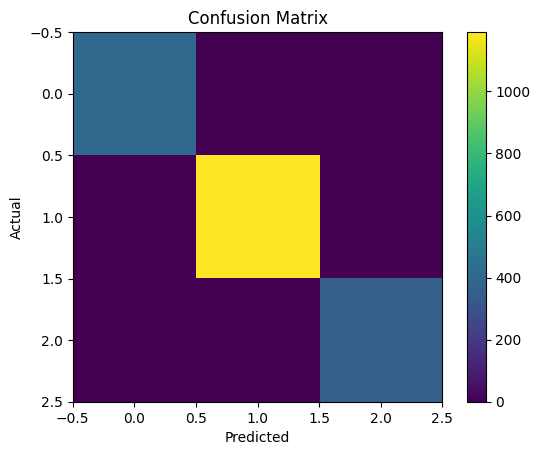

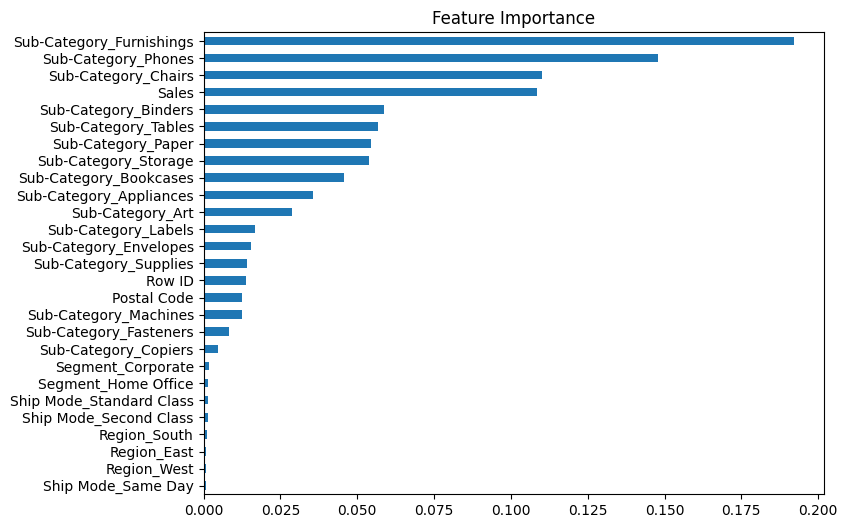

In [2]:
# Import Libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, auc

# Load Dataset
df = pd.read_csv("/content/HeartDisease.csv")

# Display Dataset
print(df.head())

# Features and Target
y = df["Category"] # Target variable

# Select numerical features
numerical_features = ['Row ID', 'Postal Code', 'Sales']
X_numerical = df[numerical_features]

# Select categorical features to be one-hot encoded
categorical_features_to_encode = ['Ship Mode', 'Segment', 'Region', 'Sub-Category']
X_categorical_encoded = pd.get_dummies(df[categorical_features_to_encode], drop_first=True)

# Concatenate numerical and one-hot encoded categorical features to form the final X
X = pd.concat([X_numerical, X_categorical_encoded], axis=1)

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train Model
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

# Classification Report
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)

plt.imshow(cm)
plt.title("Confusion Matrix")
plt.colorbar()
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ROC Curve
# Note: ROC curve is typically for binary classification. For multi-class, you might need a different approach (e.g., one-vs-rest).
# This part of the code might need further adjustment depending on the number of unique categories.
y_prob = model.predict_proba(X_test)
# For multiclass, roc_curve expects binary labels, so it needs to be adapted or used per class.
# For now, commenting out the ROC curve part as it's not directly applicable to a general multiclass 'Category' prediction without further modification.
# fpr, tpr, thresholds = roc_curve(y_test, y_prob[:, 1])
# roc_auc = auc(fpr, tpr)

# plt.plot(fpr, tpr, label="AUC = %0.2f"%roc_auc)
# plt.plot([0,1],[0,1],'--')
# plt.xlabel("False Positive Rate")
# plt.ylabel("True Positive Rate")
# plt.title("ROC Curve")
# plt.legend()
# plt.show()

# Feature Importance
importance = pd.Series(model.feature_importances_, index=X.columns)
importance.sort_values().plot(kind='barh', figsize=(8,6))
plt.title("Feature Importance")
plt.show()